# EuroLeague 2026–27 Season Forecasting

## Project Overview

This project develops a data-driven forecasting framework for the 2026–27 EuroLeague regular season.

The objective is to estimate current team strength, convert those strength estimates into game-level win probabilities and simulate the remainder of the season in order to produce probabilistic projections of the final standings.

The analysis is based on game-level data from the current EuroLeague season and combines:

- possession-adjusted performance metrics,
- Ridge regression for relative team-strength estimation,
- cross-validation for model selection and validation,
- home-court advantage estimation,
- probabilistic game forecasting,
- and Monte Carlo simulation of the remaining regular-season schedule.

At the time of the analysis, **91 games** had been completed.

The final model uses only **2026–27 current-season results**, as substantial offseason changes in rosters, coaching staffs and team roles reduce the reliability of directly transferring team strength from the previous season.

The project is designed as a reproducible forecasting system that can be updated as new EuroLeague games are completed.

## Methodology

The forecasting framework was developed using game-level data from the 2026–27 EuroLeague regular season. At the time of the analysis, 91 games had been completed across the first ten rounds of the competition.

For each game, team possessions were estimated using:

$$
Possessions = FGA + 0.44 \times FTA - ORB + TO
$$

The possession estimates of the two teams were averaged to obtain a common possession count for each game. Game margins were then normalized to 100 possessions in order to account for differences in pace.

Team strength was estimated using a Ridge regression model. Each game was represented from the home team's perspective, with the home team assigned a coefficient of +1 and the away team a coefficient of -1. The model therefore estimates a relative strength rating for every team while simultaneously estimating the league-wide home-court advantage.

Regularization strength was selected using leave-one-out cross-validation. The final model selected a Ridge penalty of 5.995 and estimated home-court advantage at approximately 3.77 points per 100 possessions.

The resulting team ratings are centered around zero, meaning that a positive rating represents performance above the current EuroLeague average and a negative rating represents performance below it.

Future game margins are estimated as:

$$
ExpectedMargin = Rating_{Home} - Rating_{Away} + HCA
$$

Expected margins are converted into win probabilities using a normal distribution. The distribution scale is based on the out-of-sample residual standard deviation of the Ridge model, estimated at approximately 15.20 points per 100 possessions.

The remaining regular-season schedule is then simulated 10,000 times using these game-level win probabilities. Each simulated season produces a final win total and ranking for every team, allowing the model to estimate projected wins as well as probabilities of finishing first, inside the Top 4, Top 6 and Top 10.

Although a previous-season prior was also tested, the final forecasting model uses only 2026–27 results. Significant offseason changes in roster composition, coaching staffs and team roles across the league reduce the assumption that 2025–26 team strength should transfer uniformly into the current season. The previous-season model is therefore treated as a sensitivity analysis rather than part of the main forecast.

## Validation

Model performance was evaluated using leave-one-out cross-validation, where each completed game was predicted using a model trained on all remaining games.

The Ridge team-strength model was compared against a simple baseline that used only the average home-court advantage and ignored differences in team quality.

The Ridge model achieved:

- **RMSE:** 15.12 points per 100 possessions  
- **MAE:** 12.65 points per 100 possessions  
- **Brier Score:** 0.2288  

The HCA-only baseline achieved:

- **RMSE:** 16.42 points per 100 possessions  
- **MAE:** 13.77 points per 100 possessions  
- **Brier Score:** 0.2547  

Relative to the baseline, the Ridge model reduced prediction error by approximately:

- **7.9% in RMSE**
- **8.1% in MAE**
- **10.2% in Brier Score**

The out-of-sample residual standard deviation was approximately **15.20 points per 100 possessions**, illustrating the substantial uncertainty that remains at the individual-game level.

These results suggest that the team-strength ratings provide meaningful predictive information beyond home-court advantage alone. However, the remaining prediction error also highlights the inherent volatility of basketball results and the limitations of forecasts based on a relatively early-season sample.

## Results and Forecast

The current-season Ridge model identifies a tightly grouped leading tier in the EuroLeague.

The four highest team-strength ratings are:

- **Panathinaikos:** +5.60
- **Crvena Zvezda:** +5.54
- **Real Madrid:** +5.53
- **Olympiacos:** +5.49

The differences between these four teams are very small, suggesting that they should be viewed as a common top-strength cluster rather than as clearly separated teams.

Using the estimated team strengths, home-court advantage and out-of-sample uncertainty, the remaining regular-season schedule was simulated **10,000 times**.

The simulation projects Olympiacos and Panathinaikos as the two strongest candidates for the top positions.

### Olympiacos forecast

- **Expected final wins:** 25.7
- **10th–90th percentile range:** 22–29 wins
- **Probability of finishing 1st:** 29.1%
- **Probability of Top 4:** 72.9%
- **Probability of Top 6:** 87.4%
- **Probability of Top 10:** 98.8%

### Panathinaikos forecast

- **Expected final wins:** 25.4
- **Probability of finishing 1st:** 24.1%
- **Probability of Top 4:** 69.1%
- **Probability of Top 6:** 85.7%
- **Probability of Top 10:** 98.6%

A second group follows closely behind, including Crvena Zvezda, Real Madrid, Hapoel Tel Aviv, Fenerbahce and Valencia. Their projected win totals remain close enough that relatively small changes in performance could significantly affect the final standings.

The Monte Carlo results should not be interpreted as deterministic predictions. They represent the distribution of possible outcomes under the assumptions of the current model and reflect the uncertainty associated with both individual games and the remaining schedule.

In [1]:
# ============================================================
# LOAD PORTFOLIO DATA FROM CSV
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import LeaveOneOut

# Folder containing the CSV datasets
DATA_DIR = Path.cwd() / "data"

# Load datasets
league_team_summary = pd.read_csv(
    DATA_DIR / "league_team_summary_2026_27.csv"
)

team_game_metrics = pd.read_csv(
    DATA_DIR / "team_game_metrics_2026_27.csv"
)

mc_summary_main = pd.read_csv(
    DATA_DIR / "monte_carlo_main_91games.csv"
)

# Check that all data loaded correctly
print("Portfolio data loaded successfully!")

print("Teams:", len(league_team_summary))
print("Team-game rows:", len(team_game_metrics))
print("Monte Carlo teams:", len(mc_summary_main))

Portfolio data loaded successfully!
Teams: 20
Team-game rows: 182
Monte Carlo teams: 20


In [2]:
# ============================================================
# REBUILD CURRENT-SEASON RIDGE RATINGS
# ============================================================

home_games = (
    team_game_metrics[
        team_game_metrics["home_away"] == "HOME"
    ]
    [[
        "gamecode",
        "team_code",
        "opponent",
        "pts",
        "opp_pts",
        "est_poss"
    ]]
    .copy()
)


home_games = home_games.rename(
    columns={
        "team_code": "home_team",
        "opponent": "away_team"
    }
)


home_games["margin100"] = (
    100
    *
    (
        home_games["pts"]
        -
        home_games["opp_pts"]
    )
    /
    home_games["est_poss"]
)


teams = sorted(
    league_team_summary[
        "team_code"
    ].unique()
)


team_index = {
    team: i
    for i, team in enumerate(teams)
}


X = np.zeros(
    (
        len(home_games),
        len(teams)
    )
)


y = home_games[
    "margin100"
].to_numpy()


for row_i, (_, game) in enumerate(
    home_games.iterrows()
):

    X[
        row_i,
        team_index[
            game["home_team"]
        ]
    ] = 1

    X[
        row_i,
        team_index[
            game["away_team"]
        ]
    ] = -1


alphas = np.logspace(
    -2,
    3,
    100
)


ridge_model = RidgeCV(
    alphas=alphas,
    cv=LeaveOneOut(),
    scoring="neg_mean_squared_error",
    fit_intercept=True
)


ridge_model.fit(
    X,
    y
)


ridge_ratings = pd.DataFrame({
    "team_code": teams,
    "ridge_rating": ridge_model.coef_
})


ridge_ratings["ridge_rating"] = (
    ridge_ratings["ridge_rating"]
    -
    ridge_ratings["ridge_rating"].mean()
)


ridge_ratings = (
    ridge_ratings
    .sort_values(
        "ridge_rating",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "Ridge alpha:",
    round(ridge_model.alpha_, 3)
)

print(
    "HCA:",
    round(ridge_model.intercept_, 2)
)

Ridge alpha: 5.995
HCA: 3.77


In [7]:
# ============================================================
# MODEL VALIDATION
# Ridge vs Home-Court-Only Baseline
# ============================================================

from sklearn.linear_model import Ridge
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    brier_score_loss
)
from scipy.stats import norm

import numpy as np
import pandas as pd

# Leave one game out at a time
loo = LeaveOneOut()

ridge_predictions = []
baseline_predictions = []
actual_results = []

for train_idx, test_idx in loo.split(X):

    X_train = X[train_idx]
    X_test = X[test_idx]

    y_train = y[train_idx]
    y_test = y[test_idx]

    # Ridge model using the selected alpha
    model = Ridge(
        alpha=ridge_model.alpha_,
        fit_intercept=True
    )

    model.fit(X_train, y_train)

    ridge_predictions.append(
        model.predict(X_test)[0]
    )

    # Baseline: average home margin in training games
    baseline_predictions.append(
        y_train.mean()
    )

    actual_results.append(y_test[0])


ridge_predictions = np.array(ridge_predictions)
baseline_predictions = np.array(baseline_predictions)
actual_results = np.array(actual_results)


# Margin prediction errors
ridge_rmse = np.sqrt(
    mean_squared_error(actual_results, ridge_predictions)
)
baseline_rmse = np.sqrt(
    mean_squared_error(actual_results, baseline_predictions)
)

ridge_mae = mean_absolute_error(
    actual_results, ridge_predictions
)
baseline_mae = mean_absolute_error(
    actual_results, baseline_predictions
)


# Residual uncertainty
residual_sd = np.std(
    actual_results - ridge_predictions,
    ddof=1
)


# Convert predicted margins to win probabilities
actual_wins = (actual_results > 0).astype(int)

ridge_prob = norm.cdf(
    ridge_predictions / residual_sd
)
baseline_prob = norm.cdf(
    baseline_predictions / residual_sd
)

ridge_brier = brier_score_loss(
    actual_wins, ridge_prob
)
baseline_brier = brier_score_loss(
    actual_wins, baseline_prob
)


# Comparison
validation_table = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "Brier"],
    "Ridge": [ridge_rmse, ridge_mae, ridge_brier],
    "HCA-only": [baseline_rmse, baseline_mae, baseline_brier]
})

validation_table["Improvement (%)"] = (
    100
    * (validation_table["HCA-only"] - validation_table["Ridge"])
    / validation_table["HCA-only"]
)

print("Games evaluated:", len(actual_results))
print("Residual SD:", round(residual_sd, 2))

display(
    validation_table.style
    .hide(axis="index")
    .format({
        "Ridge": "{:.4f}",
        "HCA-only": "{:.4f}",
        "Improvement (%)": "{:.1f}%"
    })
)

Games evaluated: 91
Residual SD: 15.2


Metric,Ridge,HCA-only,Improvement (%)
RMSE,15.1179,16.4201,7.9%
MAE,12.6530,13.7708,8.1%
Brier,0.2288,0.2547,10.2%


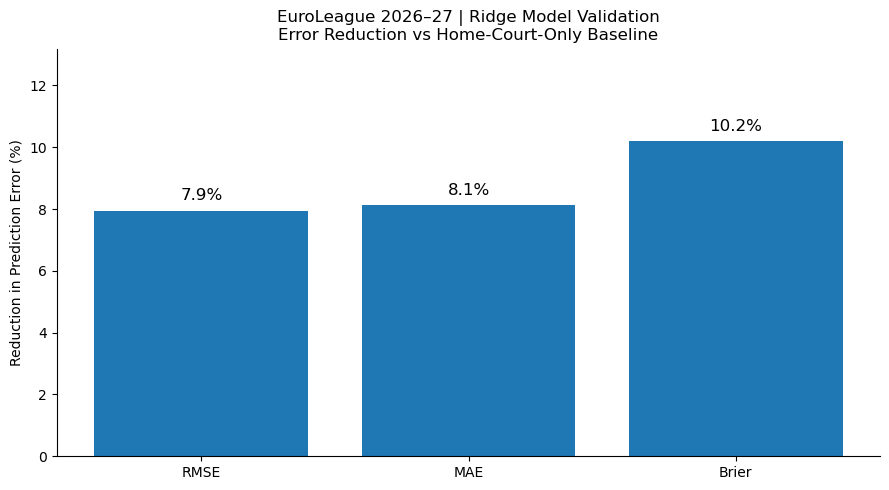

In [8]:
# ============================================================
# MODEL VALIDATION VISUAL
# Relative Error Reduction vs HCA-only Baseline
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

metrics = validation_table["Metric"].to_numpy()

improvement = validation_table[
    "Improvement (%)"
].to_numpy()

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(metrics, improvement)

ax.set_title(
    "EuroLeague 2026–27 | Ridge Model Validation\n"
    "Error Reduction vs Home-Court-Only Baseline"
)

ax.set_ylabel("Reduction in Prediction Error (%)")

ax.set_ylim(0, improvement.max() + 3)

for bar, value in zip(bars, improvement):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.25,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=12
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Projected Final Wins

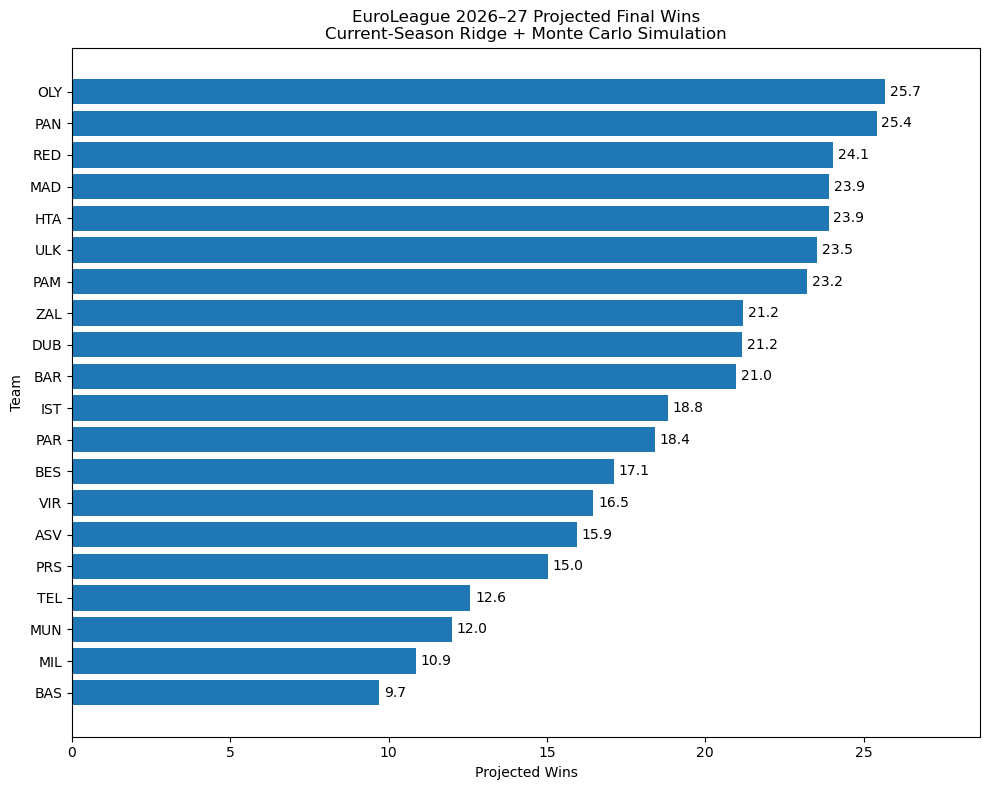

In [3]:
plot_df = (
    mc_summary_main
    .sort_values(
        "avg_wins",
        ascending=True
    )
    .copy()
)


plt.figure(
    figsize=(10, 8)
)


plt.barh(
    plot_df["team_code"],
    plot_df["avg_wins"]
)


plt.xlabel(
    "Projected Wins"
)

plt.ylabel(
    "Team"
)

plt.title(
    "EuroLeague 2026–27 Projected Final Wins\n"
    "Current-Season Ridge + Monte Carlo Simulation"
)


for i, value in enumerate(
    plot_df["avg_wins"]
):

    plt.text(
        value + 0.15,
        i,
        f"{value:.1f}",
        va="center"
    )


plt.xlim(
    0,
    plot_df["avg_wins"].max() + 3
)


plt.tight_layout()
plt.show()

### Current-Season Team Strength

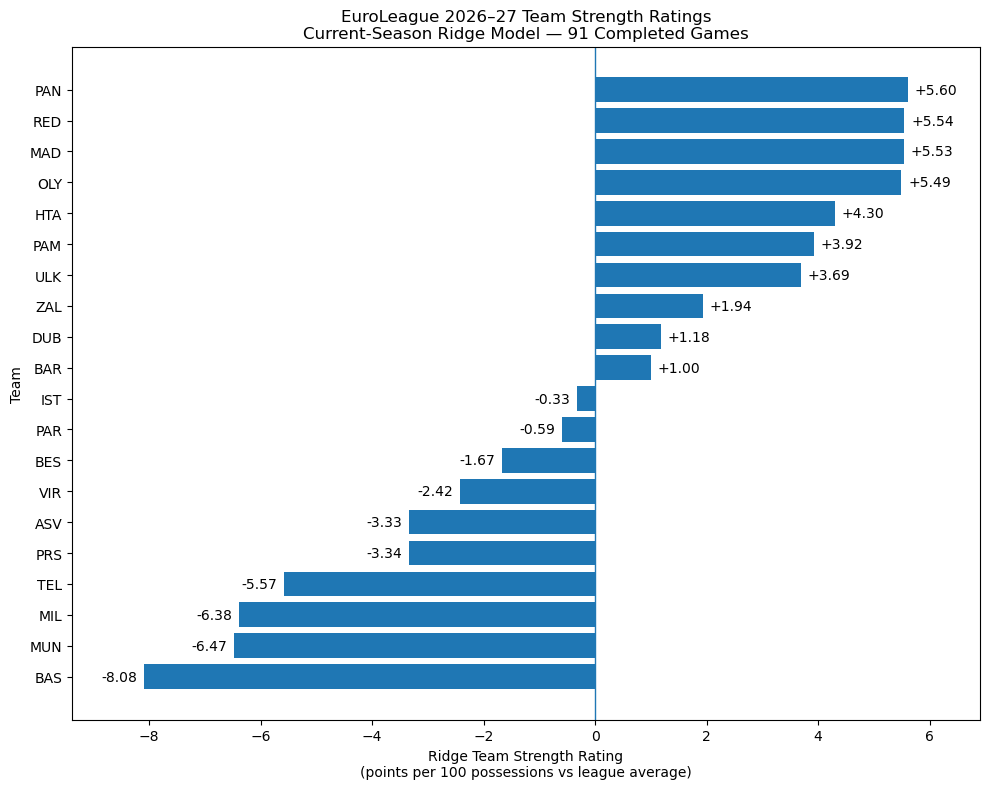

In [4]:
rating_plot = (
    ridge_ratings
    .sort_values(
        "ridge_rating",
        ascending=True
    )
    .copy()
)


plt.figure(
    figsize=(10, 8)
)


plt.barh(
    rating_plot["team_code"],
    rating_plot["ridge_rating"]
)


plt.axvline(
    0,
    linewidth=1
)


plt.xlabel(
    "Ridge Team Strength Rating\n"
    "(points per 100 possessions vs league average)"
)

plt.ylabel(
    "Team"
)

plt.title(
    "EuroLeague 2026–27 Team Strength Ratings\n"
    "Current-Season Ridge Model — 91 Completed Games"
)


for i, value in enumerate(
    rating_plot["ridge_rating"]
):

    if value >= 0:
        x_pos = value + 0.12
        ha = "left"

    else:
        x_pos = value - 0.12
        ha = "right"

    plt.text(
        x_pos,
        i,
        f"{value:+.2f}",
        va="center",
        ha=ha
    )


plt.xlim(
    rating_plot["ridge_rating"].min() - 1.3,
    rating_plot["ridge_rating"].max() + 1.3
)


plt.tight_layout()
plt.show()

### Finish Probabilities

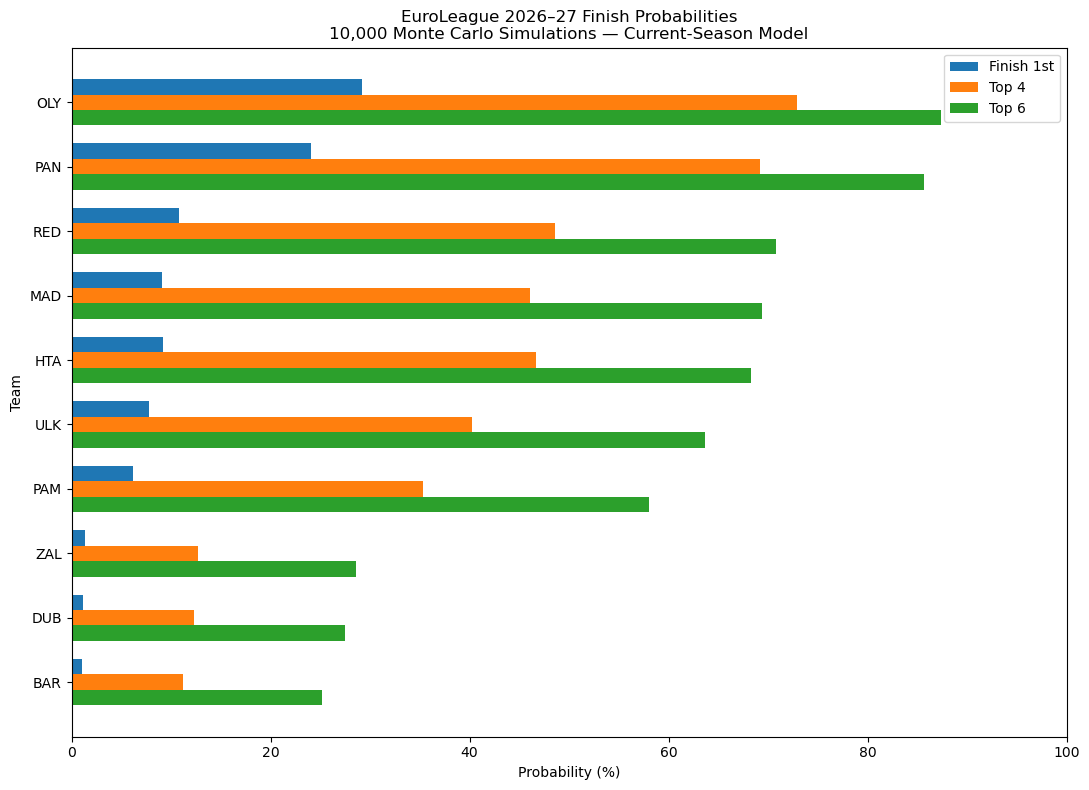

In [5]:
prob_plot = (
    mc_summary_main
    .sort_values(
        "avg_rank",
        ascending=True
    )
    .head(10)
    .copy()
)


teams_plot = (
    prob_plot["team_code"]
    .to_numpy()
)

p1 = (
    prob_plot["P1_pct"]
    .to_numpy()
)

top4 = (
    prob_plot["Top4_pct"]
    .to_numpy()
)

top6 = (
    prob_plot["Top6_pct"]
    .to_numpy()
)


y_pos = np.arange(
    len(teams_plot)
)

bar_height = 0.24


plt.figure(
    figsize=(11, 8)
)


plt.barh(
    y_pos - bar_height,
    p1,
    height=bar_height,
    label="Finish 1st"
)

plt.barh(
    y_pos,
    top4,
    height=bar_height,
    label="Top 4"
)

plt.barh(
    y_pos + bar_height,
    top6,
    height=bar_height,
    label="Top 6"
)


plt.yticks(
    y_pos,
    teams_plot
)

plt.gca().invert_yaxis()


plt.xlabel(
    "Probability (%)"
)

plt.ylabel(
    "Team"
)

plt.title(
    "EuroLeague 2026–27 Finish Probabilities\n"
    "10,000 Monte Carlo Simulations — Current-Season Model"
)


plt.xlim(
    0,
    100
)


plt.legend()

plt.tight_layout()
plt.show()

### Projected Wins and Forecast Uncertainty

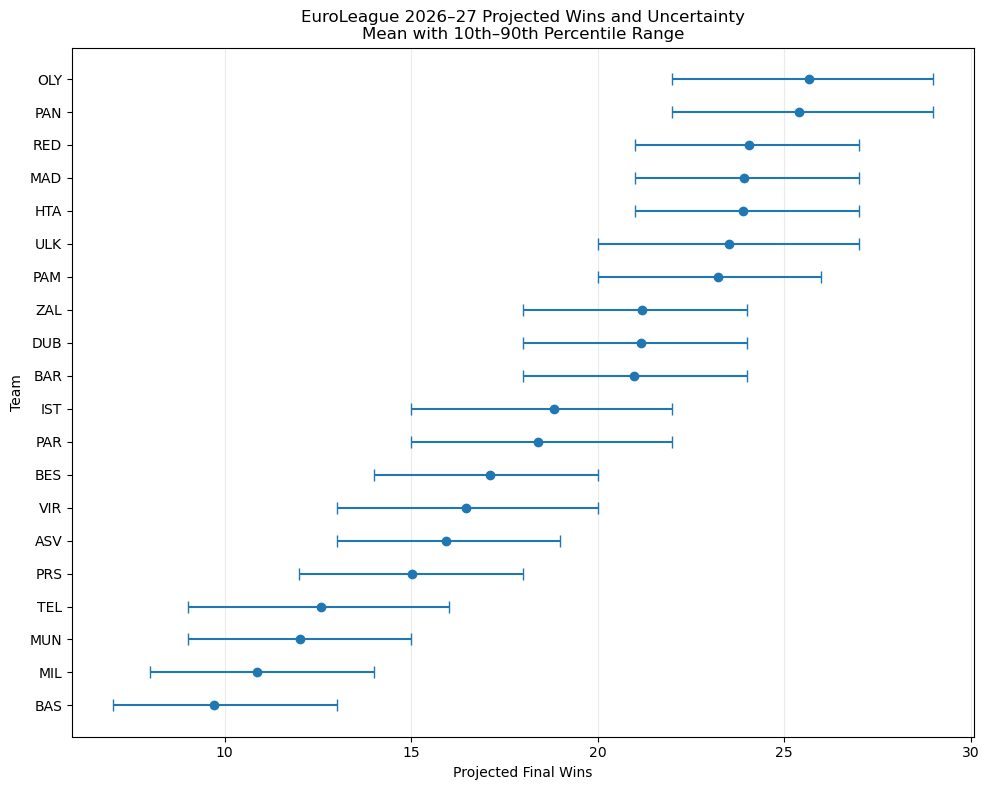

In [6]:
uncertainty_plot = (
    mc_summary_main
    .sort_values(
        "avg_wins",
        ascending=True
    )
    .copy()
)


y_pos = np.arange(
    len(uncertainty_plot)
)


avg_wins = (
    uncertainty_plot[
        "avg_wins"
    ].to_numpy()
)


lower_error = (
    avg_wins
    -
    uncertainty_plot[
        "p10_wins"
    ].to_numpy()
)


upper_error = (
    uncertainty_plot[
        "p90_wins"
    ].to_numpy()
    -
    avg_wins
)


plt.figure(
    figsize=(10, 8)
)


plt.errorbar(
    avg_wins,
    y_pos,
    xerr=[
        lower_error,
        upper_error
    ],
    fmt="o",
    capsize=4
)


plt.yticks(
    y_pos,
    uncertainty_plot[
        "team_code"
    ]
)


plt.xlabel(
    "Projected Final Wins"
)

plt.ylabel(
    "Team"
)

plt.title(
    "EuroLeague 2026–27 Projected Wins and Uncertainty\n"
    "Mean with 10th–90th Percentile Range"
)


plt.grid(
    axis="x",
    alpha=0.25
)


plt.tight_layout()
plt.show()

## Limitations

The forecasting framework has several important limitations.

First, the model is based on only **91 completed games**, meaning that the available sample remains relatively small compared with a full EuroLeague regular season. Team-strength estimates may therefore change materially as additional games are played.

Second, the model assumes that current team strength remains approximately stable for the remainder of the season. It does not explicitly account for injuries, roster changes, coaching changes, player availability, schedule congestion or changes in team form.

Third, team strength is represented by a single Ridge rating derived from game results. While this captures overall performance relative to opponents, it does not explicitly distinguish between offensive and defensive matchups, tactical styles or player-level interactions.

Win probabilities are derived from a normal distribution fitted using the model's out-of-sample residual variation. This provides a practical representation of uncertainty but may not capture the full distribution of possible game outcomes.

The Monte Carlo simulation also uses independent game outcomes. In reality, results may be correlated through factors such as injuries, fatigue, roster availability or changes in form during the season.

Finally, final standings are ranked by simulated win totals with random tie-breaking. Official EuroLeague head-to-head and other competition tie-break rules are not currently incorporated into the simulation.

For these reasons, the model should be interpreted as a probabilistic forecasting framework rather than a deterministic prediction of the final standings.

## Conclusion and Key Findings

This project developed a probabilistic forecasting framework for the 2026–27 EuroLeague regular season using current-season game-level data.

The Ridge model identifies a highly competitive leading group, with Panathinaikos, Crvena Zvezda, Real Madrid and Olympiacos producing very similar team-strength ratings. The small differences between these teams suggest that they should be interpreted as a common top tier rather than as clearly separated teams.

When the remaining schedule is simulated 10,000 times, Olympiacos and Panathinaikos emerge as the two strongest candidates for the highest positions in the standings.

Olympiacos is projected to finish with approximately **25.7 wins**, with a **29.1% probability of finishing first** and a **72.9% probability of finishing inside the Top 4**.

Panathinaikos follows closely with approximately **25.4 projected wins**, a **24.1% probability of finishing first** and a **69.1% probability of reaching the Top 4**.

The model also identifies a competitive second group consisting of Crvena Zvezda, Real Madrid, Hapoel Tel Aviv, Fenerbahce and Valencia, where relatively small differences in future performance could substantially affect final standings.

Model validation shows that the Ridge team-strength framework consistently improves upon a simple home-court-only baseline, reducing RMSE by **7.9%**, MAE by **8.1%** and Brier Score by **10.2%**.

The analysis also highlights the importance of uncertainty. Even the strongest teams retain a wide range of possible final outcomes, demonstrating why season forecasts are better interpreted probabilistically rather than as fixed predictions.

Overall, the framework provides a reproducible way to combine team-strength estimation, game-level win probabilities and Monte Carlo simulation into a single forecasting system that can be updated as new EuroLeague results become available.